# 08 · La EDR como nivel de la noche

En la feature C la EDR entra solo como **nivel de la noche**, que se compara entre personas. Este notebook revisa la EDR con ese papel en mente, solo con los registros de desarrollo:

1. **Qué banda se mide en realidad.** Si alguna etapa del pipeline pierde potencia en las frecuencias de la apnea, y cuáles.
2. **Las decisiones de la EDR**, con el criterio registrado antes de calcularlas (`docs/criterio_edr.md`).

Test no se usa.

In [1]:
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from src.config import ECG_FILTER, SPLIT_CSV
from src.data import load_apnea_labels, load_ecg
from src.features.build import record_series
from src.features.coupling import resample_uniform, welch_spectra
from src.features.detector import BAND, BANDA_EFECTIVA, FS_U, WINDOW_S
from src.features.edr import beat_edr
from src.preprocessing.wiener import wiener_from_beats
from src.qrs.beats import record_beats
from src.viz.plots import ANCHO, APNEA, GRIS, NORMAL, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()

## 1. Qué banda se mide en realidad

La banda se escribió como 0,01–0,05 Hz, porque la apnea tiene ciclos de entre 20 y 100 s (Guilleminault et al., 1984). Hay que verificar si cada etapa del pipeline deja pasar esas frecuencias. Una observación de la bibliografía motiva la pregunta: los algoritmos que estiman la frecuencia respiratoria con el ECG empiezan por eliminar todo lo que está por debajo de 0,03–0,05 Hz (Charlton et al., 2018). Este pipeline no aplica ese paso, pero conviene medir qué pasa en cada etapa.

Se miden tres etapas con simulaciones, sin etiquetas:
- el filtro del ECG y el Wiener, sobre un QRS cuya amplitud oscila lentamente;
- la interpolación a 2 Hz desde los tiempos reales de los latidos;
- el estimador de Welch con segmentos de 120 s.

### Filtro del ECG y Wiener

Se arma un ECG sintético con el latido típico de `a03`, ubicado en los tiempos reales de sus latidos (3 h), con una amplitud que oscila un 10 % a la frecuencia f, más un ruido blanco chico. Se mide la EDR (área relativa del QRS) y se estima la amplitud de la oscilación a la frecuencia f. Una ganancia de 1 quiere decir que la oscilación se conserva.

In [2]:
F_PRUEBA = 1 / np.array([100, 80, 60, 40, 30, 20, 4.0])   # períodos en s
ecg, fs = load_ecg("a03")
t_r = record_beats("a03")["t_r"]
t_r = t_r[(t_r > 10) & (t_r < 3 * 3600)]
k_r = np.rint(t_r * fs).astype(int)
pre, post = int(0.25 * fs), int(0.40 * fs)
plantilla = np.median(np.stack([ecg[i - pre:i + post + 1] for i in k_r[1:-1]]), axis=0)
plantilla = plantilla - np.linspace(plantilla[0], plantilla[-1], len(plantilla))


def amplitud_en(t, v, f):
    """Amplitud relativa de la componente de frecuencia f (mínimos cuadrados con seno, coseno y constante)."""
    X = np.c_[np.sin(2 * np.pi * f * t), np.cos(2 * np.pi * f * t), np.ones_like(t)]
    b = np.linalg.lstsq(X, v, rcond=None)[0]
    return np.hypot(b[0], b[1]) / abs(b[2])


M_MOD = 0.10
rng = np.random.default_rng(0)
filas = []
for f in F_PRUEBA:
    fase = rng.uniform(0, 2 * np.pi)
    sint = np.zeros(len(ecg))
    for ti, i in zip(t_r, k_r):
        if i - pre >= 0 and i + post + 1 <= len(ecg):
            sint[i - pre:i + post + 1] += plantilla * (1 + M_MOD * np.sin(2 * np.pi * f * ti + fase))
    sint += rng.normal(0, 0.02 * np.ptp(plantilla), len(sint))
    fila = {"f (Hz)": f, "período (s)": round(1 / f)}
    for nom, pref in (("filtro 0,5–45 Hz", None), ("filtro + Wiener", lambda s_: wiener_from_beats(s_, t_r, fs))):
        t, v = beat_edr(sint, t_r, fs, "area", ECG_FILTER, prefilter=pref, relative=True)
        fila[nom] = amplitud_en(t, v, f) / M_MOD
    filas.append(fila)
pd.DataFrame(filas).set_index("f (Hz)").rename(index=lambda x: round(x, 4)).round(3)

,período (s),"filtro 0,5–45 Hz",filtro + Wiener
f (Hz),,,
0.0100,100,0.997,0.997
0.0125,80,1.003,1.003
0.0167,60,1.008,1.007
0.0250,40,1.008,1.008
0.0333,30,0.991,0.991
0.0500,20,0.985,0.985
0.2500,4,0.987,0.987


Las dos etapas conservan la oscilación (ganancia entre 0,98 y 1,01). Actúan sobre la **forma** de cada latido, y la oscilación lenta de la apnea está en cómo cambia el latido de uno al siguiente, no en esa forma.

### Interpolación a 2 Hz

Se muestrea una sinusoide de frecuencia f en los tiempos reales de los latidos y se interpola a la grilla de 2 Hz, de forma lineal y con spline cúbico.

In [3]:
filas = []
for f in F_PRUEBA:
    s = np.sin(2 * np.pi * f * t_r)
    fila = {"f (Hz)": f, "período (s)": round(1 / f)}
    for kind, nom in (("linear", "lineal"), ("cubic", "spline cúbico")):
        tu, su = resample_uniform(t_r, s + 10, FS_U, kind)
        fila[f"{nom}: potencia que conserva"] = (amplitud_en(tu, su, f) * 10) ** 2
    filas.append(fila)
pd.DataFrame(filas).set_index("f (Hz)").rename(index=lambda x: round(x, 4)).round(3)

,período (s),lineal: potencia que conserva,spline cúbico: potencia que conserva
f (Hz),,,
0.0100,100,0.999,1.000
0.0125,80,0.999,1.000
0.0167,60,0.998,1.000
0.0250,40,0.996,1.000
0.0333,30,0.993,1.000
0.0500,20,0.985,1.000
0.2500,4,0.682,0.968


En la banda de la apnea las dos conservan prácticamente toda la potencia: la lineal pierde 1,5 % en 0,05 Hz. En la banda respiratoria (0,25 Hz) la lineal pierde un tercio y el spline cúbico, 3 %.

### El estimador de Welch

Con segmentos de 120 s, el espectro se calcula en las frecuencias k/120 Hz, y la feature suma k = 2…6. Se calcula qué fracción de la potencia de una sinusoide de frecuencia f termina en esas cinco frecuencias, promediando 16 fases, con cada forma de quitar la tendencia.

In [4]:
n_w = int(WINDOW_S * FS_U)
t_w = np.arange(n_w) / FS_U
f_cap = np.round(np.arange(0.004, 0.0701, 0.001), 4)
cap = {}
for dt, nom in (("linear", "quitando la recta"), ("constant", "quitando la media")):
    vals = []
    for f in f_cap:
        c = []
        for fase in np.linspace(0, 2 * np.pi, 16, endpoint=False):
            x = np.sin(2 * np.pi * f * t_w + fase)
            fr, sxx, _, _ = welch_spectra(x, x, FS_U, n_w // 2, dt)
            b = (fr >= BAND[0] - 1e-9) & (fr <= BAND[1] + 1e-9)
            c.append(sxx[b].sum() * (fr[1] - fr[0]) / 0.5)
        vals.append(np.mean(c))
    cap[nom] = np.array(vals)
cap = pd.DataFrame(cap, index=f_cap)
med = cap["quitando la media"].to_numpy()
i_lo = int(np.argmax(med >= 0.5)); j_hi = len(med) - 1 - int(np.argmax(med[::-1] >= 0.5))
borde_bajo = float(np.interp(0.5, med[i_lo - 1:i_lo + 1], f_cap[i_lo - 1:i_lo + 1]))
borde_alto = float(np.interp(0.5, med[j_hi:j_hi + 2][::-1], f_cap[j_hi:j_hi + 2][::-1]))
print(f"frecuencias que suma la feature (k = 2…6): {BANDA_EFECTIVA[0]:.4f} a {BANDA_EFECTIVA[1]:.4f} Hz")
print(f"mitad de potencia: {borde_bajo:.4f} Hz ({1 / borde_bajo:.0f} s) y {borde_alto:.4f} Hz ({1 / borde_alto:.0f} s)")
cap.assign(**{"período (s)": np.round(1 / cap.index)}).iloc[2::2].round(3)

frecuencias que suma la feature (k = 2…6): 0.0167 a 0.0500 Hz
mitad de potencia: 0.0125 Hz (80 s) y 0.0542 Hz (18 s)


,quitando la recta,quitando la media,período (s)
0.006,0.038,0.061,167.0
0.008,0.117,0.147,125.0
0.010,0.261,0.283,100.0
0.012,0.456,0.455,83.0
0.014,0.659,0.634,71.0
0.016,0.823,0.791,62.0
0.018,0.924,0.902,56.0
0.020,0.969,0.966,50.0
0.022,0.985,0.993,45.0
0.024,0.991,1.000,42.0


### ¿Importa lo que se pierde? El aumento con la apnea, con el doble de resolución

La banda de `01` se midió con el mismo estimador, que casi no ve por debajo de 0,017 Hz. Para no razonar en círculo, se repite con el doble de resolución: ventanas de 480 s con segmentos de 240 s (frecuencias cada 1/240 Hz). Se toman las ventanas centradas en 8 minutos seguidos de la misma clase, apnea o normal, y en cada registro con al menos 5 ventanas de cada clase se calcula el aumento de potencia con la apnea, en dB.

In [5]:
W_ALTA, SEG_ALTA = 480, 240


def espectros_por_clase(rec):
    s = record_series(rec)
    lab = load_apnea_labels(rec)
    t = s["t"]
    out = {c: {"rr": [], "edr": []} for c in ("apnea", "normal")}
    f = None
    for m in range(4, len(lab) - 4):
        bloque = lab[m - 4:m + 4]
        if (bloque < 0).any() or len(set(bloque)) > 1:
            continue
        i = int(round((60 * m - W_ALTA / 2 - t[0]) * FS_U)); n = int(W_ALTA * FS_U)
        if i < 0 or i + n > len(t):
            continue
        clase = "apnea" if bloque[0] == 1 else "normal"
        for k in ("rr", "edr"):
            f, p = welch(s[k][i:i + n], fs=FS_U, nperseg=int(SEG_ALTA * FS_U), detrend="constant", window="hann")
            out[clase][k].append(p)
    res = {k: (np.mean(out["apnea"][k], axis=0), np.mean(out["normal"][k], axis=0))
           for k in ("rr", "edr") if len(out["apnea"][k]) >= 5 and len(out["normal"][k]) >= 5}
    return f, res


with ProcessPoolExecutor(4) as ex:
    ESP = list(ex.map(espectros_por_clase, DEV))
f_alta = next(f for f, r in ESP if f is not None)
sel = (f_alta > 0) & (f_alta <= 0.08)
aumento = {}
for k in ("rr", "edr"):
    pa = np.array([r[k][0] for _, r in ESP if k in r]); pn = np.array([r[k][1] for _, r in ESP if k in r])
    aumento[k.upper()] = np.median(10 * np.log10(pa[:, sel] / pn[:, sel]), axis=0)
print("registros con al menos 5 ventanas de cada clase:", sum(1 for _, r in ESP if "rr" in r))
tab_aum = pd.DataFrame({"período (s)": np.round(1 / f_alta[sel]), **{f"aumento {k} (dB)": v for k, v in aumento.items()}},
                       index=np.round(f_alta[sel], 4)).rename_axis("f (Hz)")
tab_aum.round(1)

registros con al menos 5 ventanas de cada clase: 32


,período (s),aumento RR (dB),aumento EDR (dB)
f (Hz),,,
0.0042,240.0,0.6,0.4
0.0083,120.0,2.2,1.6
0.0125,80.0,3.8,2.6
0.0167,60.0,6.6,4.6
0.0208,48.0,7.9,5.0
0.0250,40.0,8.3,5.1
0.0292,34.0,8.0,4.6
0.0333,30.0,7.6,3.6
0.0375,27.0,6.7,2.6


PosixPath('/home/user/TP-PSB-G8/informe/figuras/08_banda_efectiva.png')

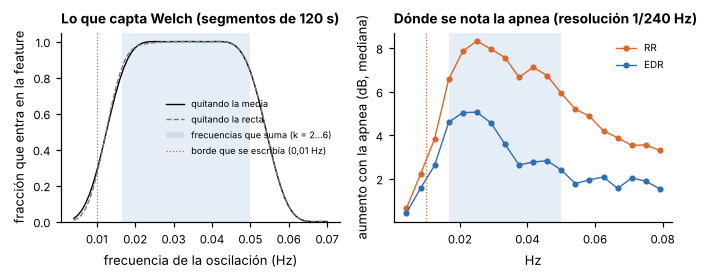

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.6))
axs[0].plot(f_cap, cap["quitando la media"], color="black", label="quitando la media")
axs[0].plot(f_cap, cap["quitando la recta"], color=GRIS, ls="--", label="quitando la recta")
axs[0].axvspan(*BANDA_EFECTIVA, color=NORMAL, alpha=0.12, lw=0, label="frecuencias que suma (k = 2…6)")
axs[0].axvline(BAND[0], color=APNEA, ls=":", lw=0.8, label="borde que se escribía (0,01 Hz)")
axs[0].set(xlabel="frecuencia de la oscilación (Hz)", ylabel="fracción que entra en la feature", ylim=(0, 1.05),
           title="Lo que capta Welch (segmentos de 120 s)")
axs[0].legend(fontsize=6)
for k, c in (("RR", APNEA), ("EDR", NORMAL)):
    axs[1].plot(f_alta[sel], aumento[k], marker="o", ms=3, color=c, label=k)
axs[1].axvspan(*BANDA_EFECTIVA, color=NORMAL, alpha=0.12, lw=0)
axs[1].axvline(BAND[0], color=APNEA, ls=":", lw=0.8)
axs[1].set(xlabel="Hz", ylabel="aumento con la apnea (dB, mediana)", title="Dónde se nota la apnea (resolución 1/240 Hz)")
axs[1].legend(fontsize=6.5)
fig.tight_layout()
save(fig, "08_banda_efectiva")

**Qué se ve.**
- **Ninguna etapa pierde la oscilación de la apnea, salvo el borde bajo de Welch.** El filtro, el Wiener y la interpolación la conservan. Welch capta entre 83 % y 100 % de las oscilaciones de 20 a 60 s; las de 60 a 100 s entran solo en parte (entre ~25 % y ~80 %), y las de más de 100 s casi nada.
- **No es la tendencia que se quita:** quitar la recta o la media da casi lo mismo. Es la resolución: con segmentos de 120 s el espectro se calcula cada 0,0083 Hz, y la ventana de Hann reparte una oscilación de 100 s entre 0,0083 Hz, que no se suma, y 0,017 Hz, que sí.
- **Lo que se pierde es lo que menos distingue la apnea.** Con el doble de resolución, el aumento con la apnea es máximo entre 40 y 48 s de período (RR ~+8 dB, EDR ~+5 dB) y baja por debajo de 0,017 Hz (en 80 s: RR ~+4 dB, EDR ~+3 dB). Por encima de 100 s casi no hay aumento: son cambios de etapa del sueño, de postura o de toda la noche, no ciclos de apnea.
- **El borde de arriba también es suave.** Entran en parte oscilaciones de 17 a 20 s, donde la apnea todavía aumenta la potencia del RR.

**Conclusión: la banda que se mide es 0,017–0,05 Hz** (las frecuencias k = 2…6), con bordes suaves que caen a la mitad de la potencia en ~80 s y ~18 s de período. El borde de 0,01 Hz que se escribía era nominal. Los cálculos no cambian, porque siempre se sumaron esas mismas cinco frecuencias. Una ventana más larga vería mejor los ciclos de 60 a 100 s, pero en desarrollo no mejoró la detección (con 360 s empeoró de forma demostrable, `04` §15): se informa como limitación.